In [2]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from modules.data_loader import *
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import OneHotEncoder
from modules.benchmark import *
%load_ext autoreload
%autoreload 2

# Random Forest

# Expert + Chen features for surfactants

In [2]:
visco = load_cleaned()
visco = drop_rheological(visco)
visco = add_expert_chen(visco, columns=['smiles_surfactant1', 'smiles_surfactant2'])
visco = drop_smiles(visco)
visco.head()

,id_surfactant1,type_surfactant1,c_surfactant1,id_surfactant2,type_surfactant2,c_surfactant2,id_additive1,c_additive1,id_additive2,c_additive2,...,surfactant2_chen_MaxAbsEStateIndex,surfactant2_chen_Balaban,surfactant2_chen_SlogP_VSA2,surfactant2_chen_HallKierAlpha,surfactant2_chen_EState_VSA5,surfactant2_chen_MaxPartialCharge,surfactant2_chen_PEOE_VSA7,surfactant2_chen_PEOE_VSA8,surfactant2_molecular_weight,surfactant2_tail_length
0,SLES,anionic,395.0,LED1A,zwitterionic,55.0,NaCl,100.0,NaN,0.0,...,11.575318,3.274503,32.137605,-1.1,51.993423,0.307938,6.420822,19.3864,313.249118,12.0
1,SLES,anionic,395.0,LED1A,zwitterionic,55.0,NaCl,150.0,NaN,0.0,...,11.575318,3.274503,32.137605,-1.1,51.993423,0.307938,6.420822,19.3864,313.249118,12.0
2,SLES,anionic,395.0,LED1A,zwitterionic,55.0,NaCl,200.0,NaN,0.0,...,11.575318,3.274503,32.137605,-1.1,51.993423,0.307938,6.420822,19.3864,313.249118,12.0
3,SLES,anionic,395.0,LED1A,zwitterionic,55.0,NaCl,250.0,NaN,0.0,...,11.575318,3.274503,32.137605,-1.1,51.993423,0.307938,6.420822,19.3864,313.249118,12.0
4,SLES,anionic,395.0,LED1A,zwitterionic,55.0,NaCl,325.0,NaN,0.0,...,11.575318,3.274503,32.137605,-1.1,51.993423,0.307938,6.420822,19.3864,313.249118,12.0


In [3]:
visco.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8185 entries, 0 to 8184
Data columns (total 54 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   id_surfactant1                      8185 non-null   object 
 1   type_surfactant1                    8185 non-null   object 
 2   c_surfactant1                       8185 non-null   float64
 3   id_surfactant2                      2727 non-null   object 
 4   type_surfactant2                    2727 non-null   object 
 5   c_surfactant2                       8185 non-null   float64
 6   id_additive1                        5519 non-null   object 
 7   c_additive1                         8185 non-null   float64
 8   id_additive2                        1279 non-null   object 
 9   c_additive2                         8185 non-null   float64
 10  temperature                         8185 non-null   int64  
 11  viscoelasticity                     8185 no

## Random forest

In [4]:
y = visco['viscoelasticity']
X = visco.drop(columns=['viscoelasticity'])
X = drop_ids(X)
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8185 entries, 0 to 8184
Data columns (total 49 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   type_surfactant1                    8185 non-null   object 
 1   c_surfactant1                       8185 non-null   float64
 2   type_surfactant2                    2727 non-null   object 
 3   c_surfactant2                       8185 non-null   float64
 4   c_additive1                         8185 non-null   float64
 5   c_additive2                         8185 non-null   float64
 6   temperature                         8185 non-null   int64  
 7   surfactant1_chen_MolLogP            8185 non-null   float64
 8   surfactant1_chen_Chi1v              8185 non-null   float64
 9   surfactant1_chen_VSA_EState7        8185 non-null   float64
 10  surfactant1_chen_VSA_EState8        8185 non-null   float64
 11  surfactant1_chen_qed                8185 no

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

categorical_features = ['type_surfactant1', 'type_surfactant2']
numerical_features = []

for column in X.columns:
    if X[column].dtype in ('float64', 'int64'):
        numerical_features.append(column)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(), categorical_features)
    ]
)

classifier = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    min_samples_leaf=5,
    min_samples_split=10
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](2,)","[0.,1.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](49,)","['type_surfactant1','c_surfactant1','type_surfactant2',..., 'surfactant2_chen_PEOE_VSA8','surfactant2_molecular_weight', 'surfactant2_tail_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,49
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns

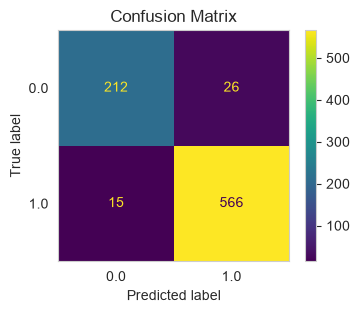

Accuracy: 0.9499389499389499


In [6]:
y_pred = model.predict(X_test)
fig, ax = plt.subplots(figsize=(4, 3))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    ax=ax
)
ax.grid(False)
plt.title("Confusion Matrix")
plt.show()
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

## Standard StratifiedKFold

In [7]:
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

accs = []

for train_idx, test_idx in skf.split(X, y):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print("Accuracy:", acc)
    accs.append(acc)

mean_acc = np.mean(accs)
std_acc = np.std(accs, ddof=1)
print(f"Mean: {mean_acc:.4f}")
print(f"Std:   {std_acc:.4f}")

Accuracy: 0.9511599511599511
Accuracy: 0.9401709401709402
Accuracy: 0.9597069597069597
Accuracy: 0.9536019536019537
Accuracy: 0.9536019536019537
Accuracy: 0.9376528117359413
Accuracy: 0.9498777506112469
Accuracy: 0.9376528117359413
Accuracy: 0.941320293398533
Accuracy: 0.9498777506112469
Mean: 0.9475
Std:   0.0077


## StratifiedGroupKFold

In [8]:
groups = visco[['id_surfactant1', 'id_surfactant2']].fillna('NONE').apply(tuple, axis=1)

accs = []

for seed in range(2):
    cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=seed)
    for train_idx, test_idx in cv.split(X, y, groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        model = Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", classifier)
        ])

        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        print("Accuracy:", acc)
        accs.append(acc)

mean_acc = np.mean(accs)
std_acc = np.std(accs, ddof=1)
print(f"Mean: {mean_acc:.4f}")
print(f"Std:   {std_acc:.4f}")

Accuracy: 0.9224224224224224
Accuracy: 0.8264462809917356
Accuracy: 0.7828947368421053
Accuracy: 0.5367647058823529
Accuracy: 0.7612359550561798
Accuracy: 0.7355889724310777
Accuracy: 0.5543478260869565
Accuracy: 0.8259860788863109
Accuracy: 0.7936893203883495
Accuracy: 0.5928571428571429
Accuracy: 0.9129564782391195
Accuracy: 0.7975708502024291
Accuracy: 0.8145695364238411
Accuracy: 0.4366576819407008
Accuracy: 0.8014981273408239
Accuracy: 0.7282608695652174
Accuracy: 0.47958115183246075
Accuracy: 0.8390804597701149
Accuracy: 0.7860576923076923
Accuracy: 0.6066115702479339
Mean: 0.7268
Std:   0.1413


In [9]:
y.sum() / len(y)

np.float64(0.7188759926695174)

#### min_leaf=10 = 0.76
#### min_leaf=20 = 0.75

In [10]:
visco = quick_load(feature='expert_chen', columns=['smiles_surfactant1', 'smiles_surfactant2'])
X, y, groups = xy_split(visco)

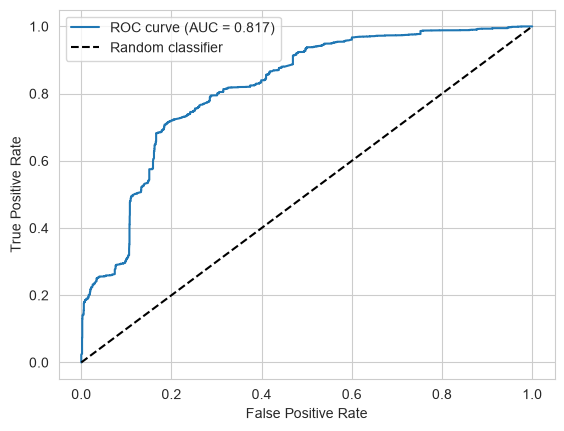

0.8165404690597975

In [11]:
groups_surf = visco[['id_surfactant1', 'id_surfactant2']].fillna('NONE').apply(tuple, axis=1)

classifier = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    min_samples_leaf=10,
    min_samples_split=20
)

simple_test(classifier, X, y, groups_surf)

In [12]:
classifier = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=10,
    min_samples_split=20
)

serial_test(classifier, X, y, groups_surf)

AUC: 0.807
AUC: 0.821
AUC: 0.826
AUC: 0.822
AUC: 0.825
AUC: 0.807
AUC: 0.835
AUC: 0.815
AUC: 0.798
AUC: 0.816
Mean: 0.8171
Std:   0.0109


## Modified grouping (now includes all compounds - see concentration_analysis)

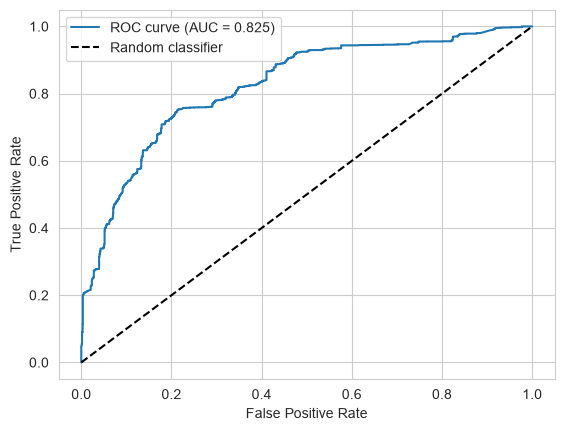

0.8245317408474606

In [13]:
classifier = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=10,
    min_samples_split=20,
    random_state=42
)

simple_test(classifier, X, y, groups)

In [14]:
classifier = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=10,
    min_samples_split=20
)

serial_test(classifier, X, y, groups)

AUC: 0.820
AUC: 0.837
AUC: 0.820
AUC: 0.828
AUC: 0.823
AUC: 0.824
AUC: 0.828
AUC: 0.829
AUC: 0.832
AUC: 0.825
Mean: 0.8267
Std:   0.0054


# Physiochemical features for surfactants

In [15]:
physio = quick_load(feature='physiochemical', columns=['smiles_surfactant1', 'smiles_surfactant2'])
X, y, groups = xy_split(physio)

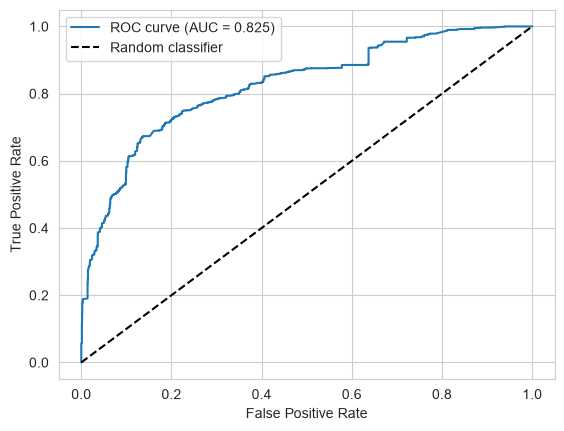

0.8250358000585565

In [16]:
classifier = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    min_samples_leaf=10,
    min_samples_split=20
)

simple_test(classifier, X, y, groups)

In [17]:
classifier = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=10,
    min_samples_split=20
)

serial_test(classifier, X, y, groups)

AUC: 0.808
AUC: 0.819
AUC: 0.820
AUC: 0.827
AUC: 0.817
AUC: 0.802
AUC: 0.822
AUC: 0.818
AUC: 0.828
AUC: 0.823
Mean: 0.8184
Std:   0.0081


# Expert + Chen features for all compounds

In [18]:
visco = quick_load(feature='expert_chen', columns=['smiles_surfactant1', 'smiles_surfactant2', 'smiles_additive1', 'smiles_additive2'])
X, y, groups = xy_split(visco)

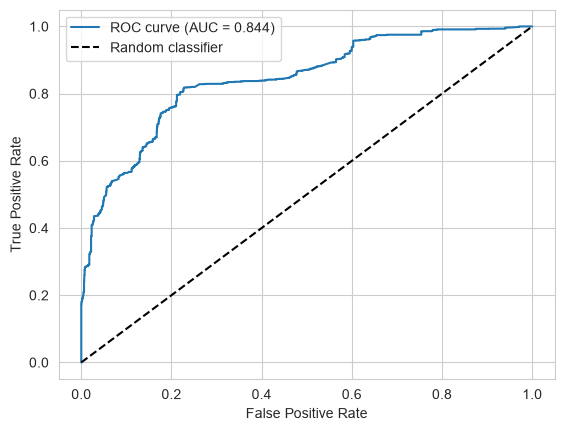

0.8438487788391001

In [19]:
classifier = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    min_samples_leaf=10,
    min_samples_split=20
)

simple_test(classifier, X, y, groups)

In [20]:
classifier = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=10,
    min_samples_split=20
)

serial_test(classifier, X, y, groups)

AUC: 0.823
AUC: 0.842
AUC: 0.845
AUC: 0.836
AUC: 0.847
AUC: 0.844
AUC: 0.843
AUC: 0.845
AUC: 0.844
AUC: 0.840
Mean: 0.8409
Std:   0.0071


# Avalon

In [3]:
visco = quick_load(feature='avalon', columns=['smiles_surfactant1', 'smiles_surfactant2', 'smiles_additive1', 'smiles_additive2'])
X, y, groups = xy_split(visco)

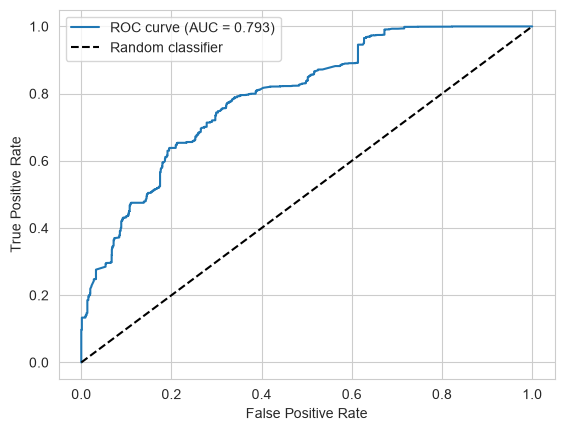

0.7925193462127867

In [4]:
classifier = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    min_samples_leaf=10,
    min_samples_split=20
)

simple_test(classifier, X, y, groups)

In [5]:
classifier = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=10,
    min_samples_split=20
)

serial_test(classifier, X, y, groups)

AUC: 0.810
AUC: 0.809
AUC: 0.807
AUC: 0.802
AUC: 0.805
AUC: 0.778
AUC: 0.814
AUC: 0.814
AUC: 0.810
AUC: 0.803
Mean: 0.8052
Std:   0.0102


# MACCS

In [6]:
visco = quick_load(feature='maccs', columns=['smiles_surfactant1', 'smiles_surfactant2', 'smiles_additive1', 'smiles_additive2'])
X, y, groups = xy_split(visco)

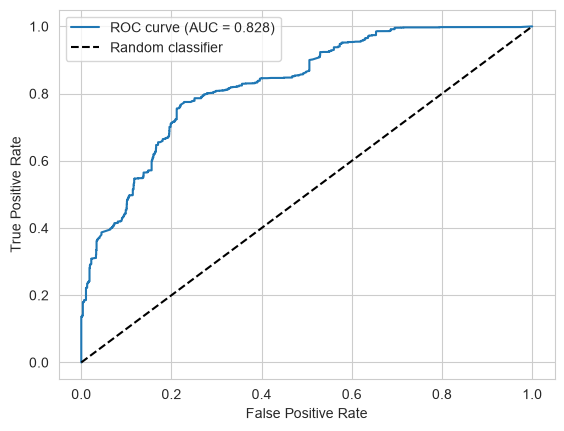

0.828398361366249

In [7]:
classifier = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    min_samples_leaf=10,
    min_samples_split=20
)

simple_test(classifier, X, y, groups)

In [8]:
classifier = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=10,
    min_samples_split=20
)

serial_test(classifier, X, y, groups)

AUC: 0.820
AUC: 0.819
AUC: 0.823
AUC: 0.820
AUC: 0.817
AUC: 0.820
AUC: 0.824
AUC: 0.807
AUC: 0.812
AUC: 0.811
Mean: 0.8173
Std:   0.0054


# BCUT2D

In [9]:
visco = quick_load(feature='bcut2d', columns=['smiles_surfactant1', 'smiles_surfactant2', 'smiles_additive1', 'smiles_additive2'])
X, y, groups = xy_split(visco)

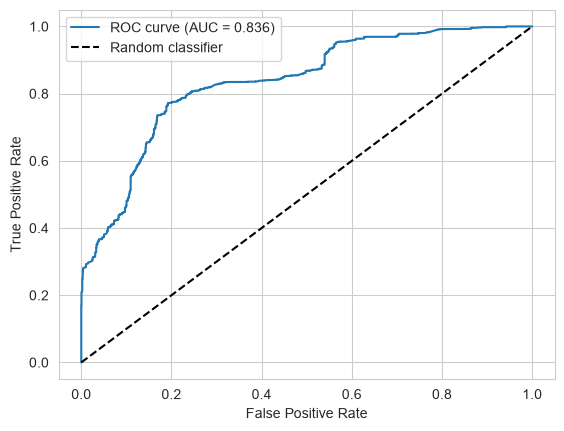

0.8364364236162506

In [10]:
classifier = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    min_samples_leaf=10,
    min_samples_split=20
)

simple_test(classifier, X, y, groups)

In [11]:
classifier = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=10,
    min_samples_split=20
)

serial_test(classifier, X, y, groups)

AUC: 0.838
AUC: 0.835
AUC: 0.833
AUC: 0.829
AUC: 0.827
AUC: 0.843
AUC: 0.842
AUC: 0.832
AUC: 0.820
AUC: 0.842
Mean: 0.8341
Std:   0.0074
